# Multi-map reward navigation: binding and bundling

Reproduces Fig. 5 (Sec. 3.3, Appendix L): several reward maps coexisting in one
population, retrieved by querying with the right context, and navigated by gradient
ascent.

Two hyperdimensional operations, both of which the framework already provides:

- **Bundling** (App. L.1) superposes the representations of rewarded locations into a
  composite memory, $p_R(s) = \frac{1}{N_R}\sum_i p(r_i, s)$. Querying it with the
  current location, $C_R(r,s) = p(r,s)^\top p_R(s)$, gives a mixture-of-Gaussians reward
  landscape — but *only* for a similarity-preserving code. A pure grid code would give a
  periodic, ambiguous one, which is why all three spectra here are Gaussian.
- **Binding** (App. L.2) is remapping. The context generator orthogonalises the maps, so
  memories from different contexts can be summed into one vector (Eq. 9) and pulled apart
  again by querying with the right $s$.

Three rewards, as in Fig. 5: two *Food* items and one *Home*, in two contexts.

**Parameters.** $N = 300$ is the Fig. 5 caption; $s \in [0,5]$ is Appendix A. The arena is
$[-3,3]$, as in the original notebook, rather than Appendix A's $[-2,2]$ for the
similarity-preserving experiments — three rewards need the extra room to sit more than a
similarity width apart.

The Gaussian spectra in `data/parameters/sigma_*_pc.pt` cannot be reconstructed without
their seed, which was never recorded, so this notebook draws equivalent seeded ones.

Note that `expmap.remapping_model` is *not* the right constructor here: it pairs a
roots-of-unity spatial spectrum with a Gaussian context one. This figure needs Gaussian
spectra on all three axes, so the generators are built explicitly.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from expmap.generators import block_diag_skew, build_generators_with_context, gaussian_eigenvalues
from expmap.linalg import random_orthogonal_matrix, starting_state
from expmap.model import RemappingModel
from expmap.navigation import bind, bundle, query, similarity_gradient
from expmap.plotting import ratemap_collage

# Figure parameters. N = 300 is the Fig. 5 caption; the context shift 0 -> 5 is Appendix A.
N = 300
SCALE = np.sqrt(2)
ARENA_SIZE = 3.0
BINS = 32
S_FOOD, S_HOME = 0.0, 5.0
SEED = 0

# Reward sites in arena coordinates, matching the bins the original notebook indexed.
FOOD = torch.tensor([[1.8, 0.1], [-1.0, -2.0]])
HOME = torch.tensor([[-1.6, 2.2]])

START = torch.tensor([0.9, 0.8])  # where the agent begins foraging
ETA, N_STEPS = 1.5, 40

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

In [2]:
# All three spectra Gaussian: space must be similarity-preserving for the bundled landscape
# to be a smooth mixture of Gaussians rather than a periodic one.
ev_x = gaussian_eigenvalues(N, scale=SCALE, seed=SEED)
ev_y = gaussian_eigenvalues(N, scale=SCALE, seed=SEED + 1)
ev_s = gaussian_eigenvalues(N, scale=SCALE, seed=SEED + 2)
sigma_x, sigma_y, sigma_s = (block_diag_skew(ev) for ev in (ev_x, ev_y, ev_s))

R = random_orthogonal_matrix(N, seed=SEED)
p0 = starting_state(R)
Gx, Gy, Gs = build_generators_with_context(sigma_x, sigma_y, sigma_s, R)

model = RemappingModel(Gx, Gy, Gs)

for name, G in [("Gx", Gx), ("Gy", Gy), ("Gs", Gs)]:
    assert torch.allclose(G, -G.T, atol=1e-6), f"{name} must be skew-symmetric"
assert torch.allclose(Gx @ Gs, Gs @ Gx, atol=1e-5), "Gs must commute with Gx"

print(f"Number of units: {N}")

Number of units: 300


||p|| = 1.000000


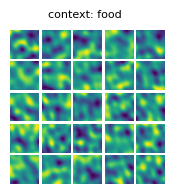

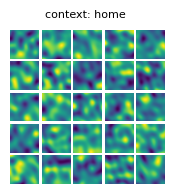

In [3]:
# Evaluate on the exact grid of bin centres rather than binning random samples. The maps
# here are smooth and the reward markers need to land on the right pixel, so exact
# evaluation is both cheaper (1024 positions instead of 25 000) and free of binning noise.
edges = np.linspace(-ARENA_SIZE, ARENA_SIZE, BINS + 1)
centres = (edges[:-1] + edges[1:]) / 2
X, Y = np.meshgrid(centres, centres, indexing="ij")
grid = torch.tensor(np.stack([X.ravel(), Y.ravel()], axis=1), dtype=torch.float32)

with torch.no_grad():
    p_food_ctx = model(grid, p0, context=S_FOOD)
    p_home_ctx = model(grid, p0, context=S_HOME)

ratemaps_food = p_food_ctx.numpy().T.reshape(N, BINS, BINS)
ratemaps_home = p_home_ctx.numpy().T.reshape(N, BINS, BINS)

print(f"||p|| = {p_food_ctx.norm(dim=1).mean():.6f}")

for ratemaps, label in [(ratemaps_food, "food"), (ratemaps_home, "home")]:
    fig, _ = ratemap_collage(ratemaps, rows=5, cols=5, figsize=(2, 2))
    fig.suptitle(f"context: {label}", fontsize=8)
    fig.savefig(FIGURE_DIR / f"pc_ratemaps_{label}.png", dpi=300, bbox_inches="tight")

In [4]:
# App. L.1: bundle within a context (the mean). Eq. 9: bind across contexts (the sum).
with torch.no_grad():
    memory_food = bundle(model(FOOD, p0, context=S_FOOD))
    memory_home = bundle(model(HOME, p0, context=S_HOME))

composite = bind([memory_food, memory_home])

# The reward landscape is the composite queried at every location, in a given context.
with torch.no_grad():
    landscape_food = query(p_food_ctx, composite).numpy().reshape(BINS, BINS)
    landscape_home = query(p_home_ctx, composite).numpy().reshape(BINS, BINS)

print(f"composite memory: {tuple(composite.shape)}")

composite memory: (300,)


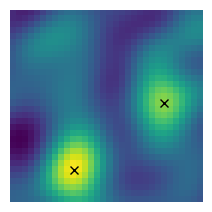

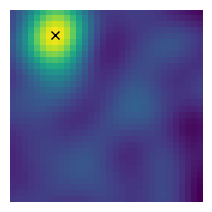

In [5]:
# Fig. 5, top left and top right: the same composite memory, queried in the two contexts.
# Querying with "food" surfaces the two food items; querying with "home" surfaces home.
extent = (-ARENA_SIZE, ARENA_SIZE, -ARENA_SIZE, ARENA_SIZE)

for landscape, sites, name in [
    (landscape_food, FOOD, "pc_rewarded_ratemap1"),
    (landscape_home, HOME, "pc_rewarded_ratemap2"),
]:
    plt.figure(figsize=(2.5, 2.5))
    # .T because the landscape is indexed (bins_x, bins_y) and imshow wants (row=y, col=x).
    plt.imshow(landscape.T, extent=extent, origin="lower")
    plt.plot(sites[:, 0], sites[:, 1], "kx")
    plt.axis("off")
    plt.savefig(FIGURE_DIR / f"{name}.svg", dpi=300, bbox_inches="tight")
    plt.savefig(FIGURE_DIR / f"{name}.png", dpi=300, bbox_inches="tight")

ended 0.031 from the nearest food site


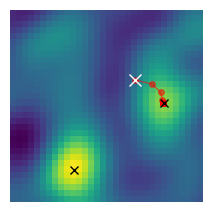

In [6]:
# Fig. 5, bottom right: gradient ascent on the retrieved landscape, r <- r + eta * grad C
# (App. L.1). similarity_gradient evaluates the gradient in closed form, so this is the
# continuous update of the paper rather than a finite difference between ratemap bins.
position = START.clone()
trajectory = [position.clone()]

for _ in range(N_STEPS):
    gradient = similarity_gradient(model, position, composite, p0, context=S_FOOD)
    position = torch.clamp(position + ETA * gradient, -ARENA_SIZE, ARENA_SIZE)
    trajectory.append(position.clone())

trajectory = torch.stack(trajectory).numpy()
reached = np.linalg.norm(FOOD.numpy() - trajectory[-1], axis=1).min()

plt.figure(figsize=(2.5, 2.5))
plt.imshow(landscape_food.T, extent=extent, origin="lower")
plt.plot(trajectory[:, 0], trajectory[:, 1], "o-", color="red", alpha=0.5, markersize=4, linewidth=1)
plt.plot(*START, "wx", markersize=8)
plt.plot(FOOD[:, 0], FOOD[:, 1], "kx")
plt.axis("off")
plt.savefig(FIGURE_DIR / "reward_gradient_navigation.svg", dpi=300, bbox_inches="tight")
plt.savefig(FIGURE_DIR / "reward_gradient_navigation.png", dpi=300, bbox_inches="tight")

print(f"ended {reached:.3f} from the nearest food site")

In [7]:
# What the figure claims, checked.
#
# 1. Binding retrieves the right map: the same composite, queried in each context, should
#    score high at that context's sites and be suppressed at the other's.
sites = {"FOOD1": FOOD[0], "FOOD2": FOOD[1], "HOME": HOME[0]}
for context, label in [(S_FOOD, "food"), (S_HOME, "home")]:
    with torch.no_grad():
        scores = {n: query(model(s[None], p0, context=context)[0], composite).item() for n, s in sites.items()}
    print(f"  context={label:5s}: " + "  ".join(f"{n}={v:+.3f}" for n, v in scores.items()))

# 2. The landscape is a mixture of Gaussians, so gradient ascent is *local*. The signal
#    exp(-d^2) falls below the finite-N ripple 1/sqrt(N/2) at around d = 1.5, which sets the
#    basin of attraction. Starting outside it, the agent climbs a ripple instead.
noise_floor = 1 / np.sqrt(N // 2)
distance = np.sqrt((X - FOOD[0, 0].item()) ** 2 + (Y - FOOD[0, 1].item()) ** 2)
print(f"\n  finite-N ripple 1/sqrt(N/2)      = {noise_floor:.3f}")
print(f"  landscape within 0.5 of FOOD1    = {landscape_food[distance < 0.5].mean():+.3f}")
print(f"  landscape at 1.5-2.0 from FOOD1  = {landscape_food[(distance > 1.5) & (distance < 2.0)].mean():+.3f}")
print(f"  -> signal exceeds ripple out to roughly d = {np.sqrt(-np.log(noise_floor)):.1f}")

  context=food : FOOD1=+0.365  FOOD2=+0.473  HOME=+0.154
  context=home : FOOD1=+0.041  FOOD2=+0.112  HOME=+0.949

  finite-N ripple 1/sqrt(N/2)      = 0.082
  landscape within 0.5 of FOOD1    = +0.330
  landscape at 1.5-2.0 from FOOD1  = +0.033
  -> signal exceeds ripple out to roughly d = 1.6
